In [2]:
import pandas as pd

titles = pd.read_csv("titles.csv")
credits = pd.read_csv("credits.csv")

print("Both datasets loaded successfully!")

Both datasets loaded successfully!


In [3]:
titles.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


In [4]:
credits.head()

,person_id,id,name,character,role
0,59401,ts20945,Joe Besser,Joe,ACTOR
1,31460,ts20945,Moe Howard,Moe,ACTOR
2,31461,ts20945,Larry Fine,Larry,ACTOR
3,21174,tm19248,Buster Keaton,Johnny Gray,ACTOR
4,28713,tm19248,Marion Mack,Annabelle Lee,ACTOR


In [6]:
print("Titles Dataset:", titles.shape)

print("Credits Dataset:", credits.shape)

Titles Dataset: (9871, 15)
Credits Dataset: (124235, 5)


In [7]:
print("Titles Columns:")
print(titles.columns)

print("Credits Columns:")
print(credits.columns)

Titles Columns:
Index(['id', 'title', 'type', 'description', 'release_year',
       'age_certification', 'runtime', 'genres', 'production_countries',
       'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
       'tmdb_score'],
      dtype='object')
Credits Columns:
Index(['person_id', 'id', 'name', 'character', 'role'], dtype='object')


In [8]:
print("Missing Values in Titles Dataset:")
print(titles.isnull().sum())

print("\nMissing Values in Credits Dataset:")
print(credits.isnull().sum())

Missing Values in Titles Dataset:
id                         0
title                      0
type                       0
description              119
release_year               0
age_certification       6487
runtime                    0
genres                     0
production_countries       0
seasons                 8514
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2082
dtype: int64

Missing Values in Credits Dataset:
person_id        0
id               0
name             0
character    16287
role             0
dtype: int64


In [9]:
print("Duplicate rows in Titles:", titles.duplicated().sum())

print("Duplicate rows in Credits:", credits.duplicated().sum())

Duplicate rows in Titles: 3
Duplicate rows in Credits: 56


In [10]:
print("Titles Dataset Information:")
titles.info()

print("\nCredits Dataset Information:")
credits.info()

Titles Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   object 
 1   title                 9871 non-null   object 
 2   type                  9871 non-null   object 
 3   description           9752 non-null   object 
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   object 
 8   production_countries  9871 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   object 
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float6

In [11]:
print("Duplicate IDs in Titles:")
print(titles["id"].duplicated().sum())

print("Duplicate IDs in Credits:")
print(credits["id"].duplicated().sum())

Duplicate IDs in Titles:
3
Duplicate IDs in Credits:
115374


In [12]:
titles = titles.drop_duplicates(subset="id", keep="first")

print("Titles dataset after removing duplicate IDs:")
print(titles.shape)

Titles dataset after removing duplicate IDs:
(9868, 15)


In [13]:
print("Remaining duplicate IDs:")
print(titles["id"].duplicated().sum())

Remaining duplicate IDs:
0


In [14]:
credits_summary = credits.groupby(["id", "role"]).size().unstack(fill_value=0)

credits_summary = credits_summary.rename(columns={
    "ACTOR": "actor_count",
    "DIRECTOR": "director_count"
})

credits_summary.head()


role,actor_count,director_count
id,,
tm100001,13,1
tm1000022,4,1
tm1000169,7,2
tm1000203,11,1
tm1000290,15,1


In [15]:
merged_data = pd.merge(
    titles,
    credits_summary,
    on="id",
    how="left"
)

print("Datasets merged successfully!")
print("Merged Dataset Shape:", merged_data.shape)

Datasets merged successfully!
Merged Dataset Shape: (9868, 17)


In [16]:
merged_data.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,actor_count,director_count
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,3.0,0.0
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0,22.0,2.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8,30.0,1.0
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4,35.0,1.0
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6,19.0,1.0


In [17]:
print("Total Rows:", merged_data.shape[0])
print("Total Columns:", merged_data.shape[1])

print("Duplicate IDs:", merged_data["id"].duplicated().sum())

Total Rows: 9868
Total Columns: 17
Duplicate IDs: 0


In [18]:
merged_data.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,actor_count,director_count
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,3.0,0.0
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0,22.0,2.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8,30.0,1.0
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4,35.0,1.0
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6,19.0,1.0


In [19]:
merged_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9868 entries, 0 to 9867
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9868 non-null   object 
 1   title                 9868 non-null   object 
 2   type                  9868 non-null   object 
 3   description           9749 non-null   object 
 4   release_year          9868 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9868 non-null   int64  
 7   genres                9868 non-null   object 
 8   production_countries  9868 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9201 non-null   object 
 11  imdb_score            8847 non-null   float64
 12  imdb_votes            8837 non-null   float64
 13  tmdb_popularity       9321 non-null   float64
 14  tmdb_score            7788 non-null   float64
 15  actor_count          

In [20]:
print(merged_data["type"].value_counts())

type
MOVIE    8511
SHOW     1357
Name: count, dtype: int64


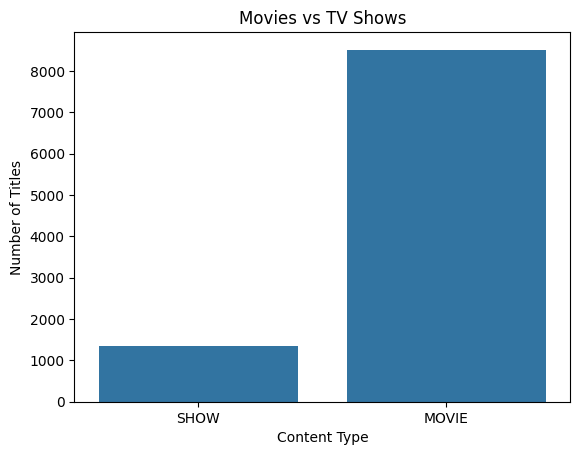

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=merged_data, x="type")

plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

In [22]:
import ast

def parse_genres(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError):
        return []

genre_counts = merged_data["genres"].apply(parse_genres).explode().value_counts()

print(genre_counts.head(10))

genres
drama            4762
comedy           2987
thriller         2119
action           1820
romance          1751
crime            1250
documentation    1096
horror           1065
family            751
european          712
Name: count, dtype: int64


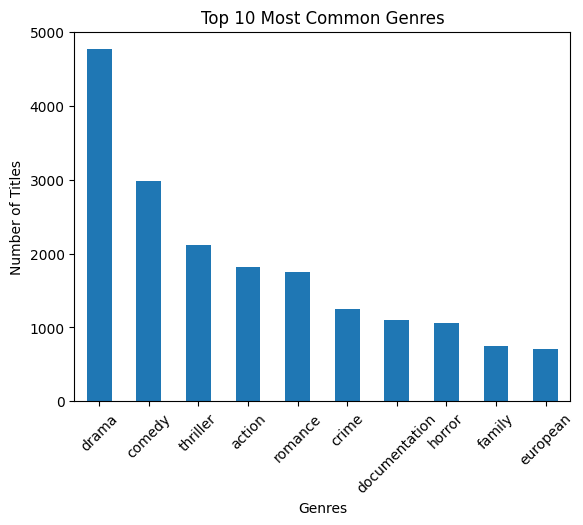

In [23]:
genre_counts.head(10).plot(kind="bar")

plt.title("Top 10 Most Common Genres")
plt.xlabel("Genres")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

In [24]:
print("Average IMDb Rating:", merged_data["imdb_score"].mean())
print("Median IMDb Rating:", merged_data["imdb_score"].median())

Average IMDb Rating: 5.9765344184469305
Median IMDb Rating: 6.1


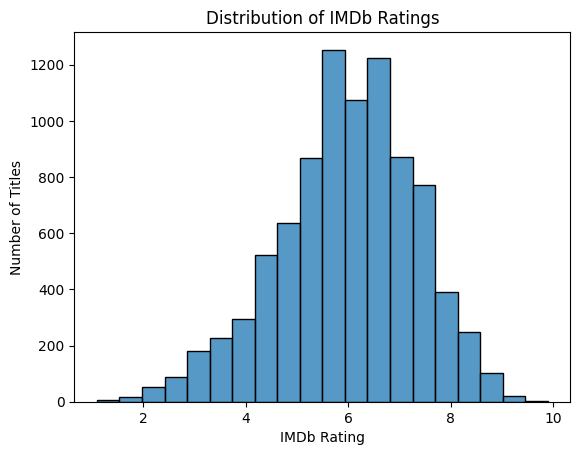

In [25]:
sns.histplot(data=merged_data, x="imdb_score", bins=20)

plt.title("Distribution of IMDb Ratings")
plt.xlabel("IMDb Rating")
plt.ylabel("Number of Titles")
plt.show()

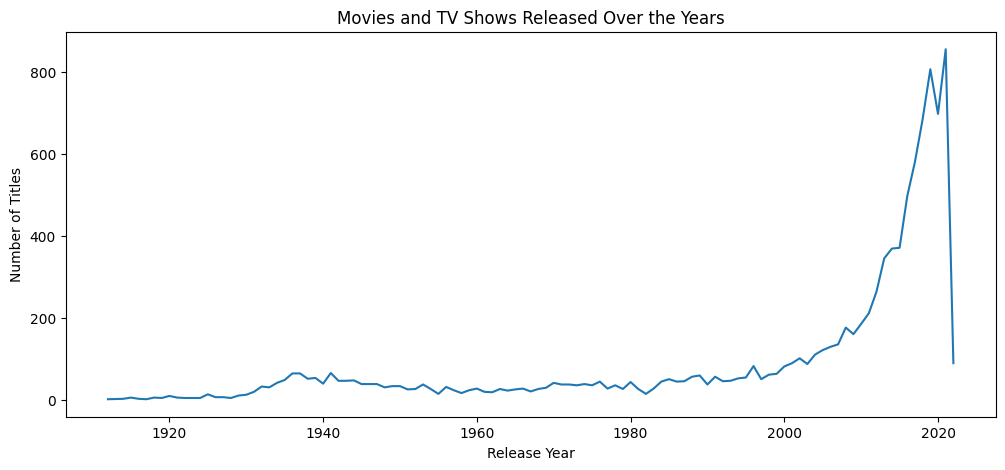

In [26]:
year_counts = merged_data["release_year"].value_counts().sort_index()

year_counts.plot(kind="line", figsize=(12,5))

plt.title("Movies and TV Shows Released Over the Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

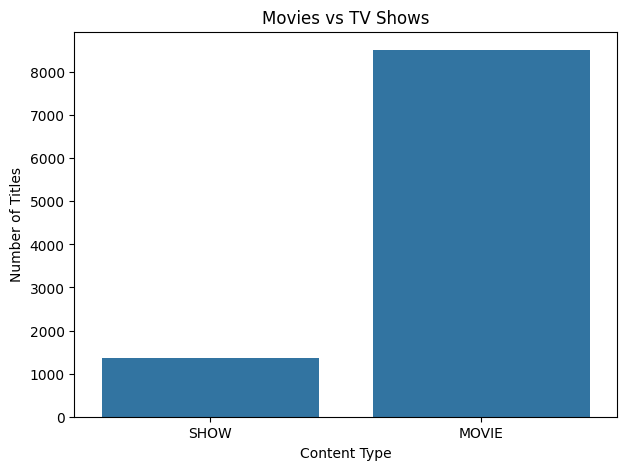

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))
sns.countplot(data=merged_data, x="type")
plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

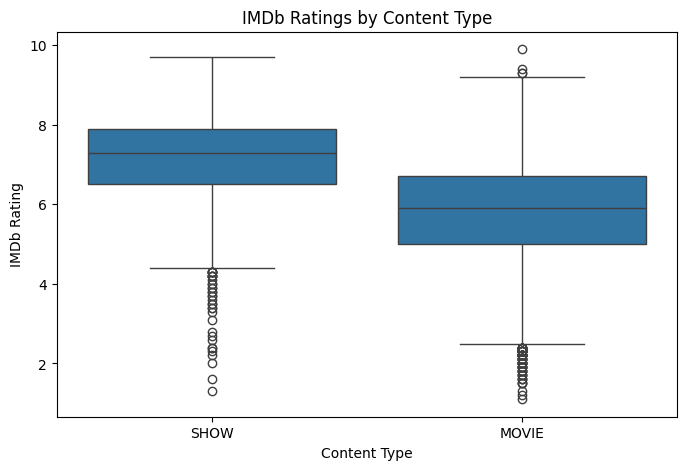

In [28]:
plt.figure(figsize=(8,5))
sns.boxplot(data=merged_data, x="type", y="imdb_score")
plt.title("IMDb Ratings by Content Type")
plt.xlabel("Content Type")
plt.ylabel("IMDb Rating")
plt.show()

In [29]:
import os

os.makedirs("Graphs", exist_ok=True)

print("Graphs folder created successfully!")


Graphs folder created successfully!


In [30]:
plt.savefig("Graphs/graph_name.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

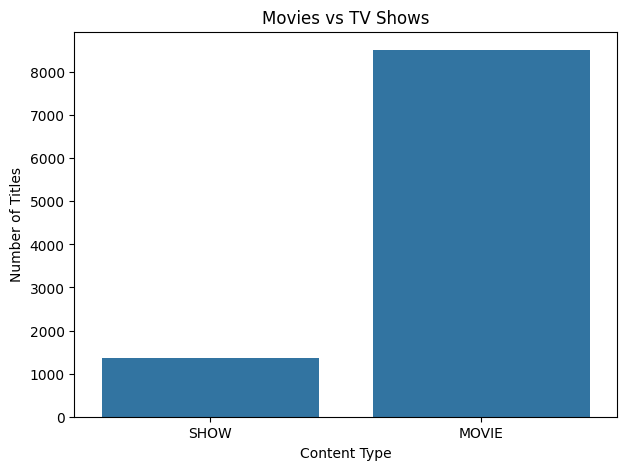

In [31]:
plt.figure(figsize=(7,5))
sns.countplot(data=merged_data, x="type")
plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.savefig("Graphs/movies_vs_tv_shows.png", dpi=300, bbox_inches="tight")
plt.show()

In [32]:
print(os.listdir("Graphs"))

['graph_name.png', 'movies_vs_tv_shows.png']


In [33]:
import os

os.makedirs("Graphs", exist_ok=True)

print("Graphs folder created successfully!")

Graphs folder created successfully!


In [34]:
plt.savefig(
    "Graphs/movies_vs_tv_shows.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>

In [35]:
print(os.listdir("Graphs"))

['graph_name.png', 'movies_vs_tv_shows.png']


# Exploratory Data Analysis (EDA) – Amazon Prime Movies and TV Shows

## 1. Introduction
The purpose of this project is to explore and analyze the Amazon Prime Movies and TV Shows dataset. The analysis helps us understand the content available, its genres, ratings, release years, and production countries.

## 2. Dataset Description
Two datasets, Titles and Credits, were used in this project.

- Titles dataset: Contains information about movies and TV shows.
- Credits dataset: Contains information about actors, directors, and their roles.

Both datasets were combined using the common ID column.

## 3. Data Cleaning
- Checked missing values.
- Checked duplicate records.
- Removed duplicate title IDs from the Titles dataset.
- Prepared the Credits dataset for merging.
- Combined both datasets using a Left Join.

## 4. Exploratory Data Analysis
The following areas were explored through graphs:

- Distribution of Movies and TV Shows.
- Most common genres.
- Top production countries.
- Runtime distribution.
- IMDb rating distribution.
- Ratings by content type.
- Top directors.

## 5. Key Insights
The observations will be added after reviewing the actual graphs and their results.

## 6. Conclusion
This EDA project helps us understand the structure and characteristics of the Amazon Prime Movies and TV Shows dataset. Data visualization makes it easier to identify patterns and summarize useful information.

In [36]:
print("========== AMAZON PRIME DATA INSIGHTS ==========")

# 1. Movies vs TV Shows
print("\n1. Content Type:")
print(merged_data["type"].value_counts())

# 2. Average IMDb Rating
print("\n2. Average IMDb Rating:")
print(merged_data["imdb_score"].mean())

# 3. Highest and Lowest IMDb Rating
print("\n3. IMDb Rating Range:")
print("Highest:", merged_data["imdb_score"].max())
print("Lowest:", merged_data["imdb_score"].min())

# 4. Release Year
print("\n4. Release Year Range:")
print("Oldest:", merged_data["release_year"].min())
print("Newest:", merged_data["release_year"].max())

# 5. Runtime
print("\n5. Average Runtime:")
print(merged_data["runtime"].mean())

# 6. Top Directors
print("\n6. Top 5 Directors:")
print(
    credits[credits["role"] == "DIRECTOR"]["name"]
    .value_counts()
    .head(5)
)

print("\n========== ANALYSIS COMPLETED ==========")

========== AMAZON PRIME DATA INSIGHTS ==========

1. Content Type:
type
MOVIE    8511
SHOW     1357
Name: count, dtype: int64

2. Average IMDb Rating:
5.9765344184469305

3. IMDb Rating Range:
Highest: 9.9
Lowest: 1.1

4. Release Year Range:
Oldest: 1912
Newest: 2022

5. Average Runtime:
85.97912444264288

6. Top 5 Directors:
name
Joseph Kane        41
Sam Newfield       38
Jay Chapman        34
Lesley Selander    22
John English       21
Name: count, dtype: int64

========== ANALYSIS COMPLETED ==========


In [37]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 10.4 MB/s  0:00:00


In [39]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors

pdf = SimpleDocTemplate(
    "Amazon_Prime_Insights_Report.pdf",
    pagesize=A4
)

styles = getSampleStyleSheet()

story = []

story.append(Paragraph(
    "Amazon Prime Movies and TV Shows – EDA Report",
    styles["Title"]
))
story.append(Spacer(1, 20))

sections = [
    ("1. Introduction",
     "This project explores the Amazon Prime Movies and TV Shows dataset using Exploratory Data Analysis (EDA)."),

    ("2. Dataset Description",
     "The project uses two datasets: Titles and Credits. They were combined using the common ID column."),

    ("3. Data Cleaning",
     "Missing values and duplicate records were examined. Duplicate title IDs were handled before merging."),

    ("4. EDA Performed",
     "The analysis includes content type, genres, production countries, runtime, IMDb ratings, release years and directors."),

    ("5. Key Insights",
     "Key findings will be added after reviewing the actual statistical results and graphs."),

    ("6. Conclusion",
     "The analysis helps identify patterns and understand the characteristics of the available content.")
]

for heading, content in sections:
    story.append(Paragraph(heading, styles["Heading2"]))
    story.append(Spacer(1, 6))
    story.append(Paragraph(content, styles["BodyText"]))
    story.append(Spacer(1, 14))

pdf.build(story)

print("PDF created successfully!")

PDF created successfully!


In [40]:
import os
from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak
)
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import inch

pdf = SimpleDocTemplate(
    "Amazon_Prime_Insights_Report.pdf",
    pagesize=A4
)

styles = getSampleStyleSheet()
story = []

story.append(Paragraph(
    "Amazon Prime Movies and TV Shows – EDA Report",
    styles["Title"]
))
story.append(Spacer(1, 20))

story.append(Paragraph(
    "Exploratory Data Analysis",
    styles["Heading1"]
))
story.append(Paragraph(
    "This report presents visual analysis of the Amazon Prime dataset.",
    styles["BodyText"]
))
story.append(Spacer(1, 20))

# Add all saved graphs
graph_files = sorted(os.listdir("Graphs"))

for filename in graph_files:
    if filename.lower().endswith((".png", ".jpg", ".jpeg")):
        story.append(Paragraph(filename.replace("_", " ").rsplit(".", 1)[0],
                               styles["Heading2"]))
        story.append(Spacer(1, 8))

        img = Image(os.path.join("Graphs", filename))
        img._restrictSize(6 * inch, 4 * inch)
        story.append(img)
        story.append(Spacer(1, 20))

pdf.build(story)

print("Updated PDF with graphs created successfully!")

Updated PDF with graphs created successfully!
